# Exploratory Data Analysis (EDA) — FER-2013 Grayscale Facial Expression Dataset

**Proyek:** Klasifikasi Ekspresi Wajah Manusia pada Citra Grayscale (FER-2013) Menggunakan Convolutional Neural Network  
**Tahap:** Tahap 2 — Exploratory Data Analysis (EDA)  
**Sumber Data:** `data/raw/train/` dan `data/raw/test/` (data aktual, *read-only*)  
**Output Visualisasi:** `outputs/figures/`

## Tujuan & Batasan Metodologis
1. Menganalisis distribusi jumlah gambar tiap kelas ekspresi wajah pada **TRAIN** dan memvisualisasikannya dengan *bar chart*.
2. Menampilkan contoh citra grayscale asli dari seluruh **7 kelas** pada **TRAIN**.
3. Memeriksa ukuran file, dimensi spasial, mode warna/kanal, dan format citra pada **TRAIN**.
4. Memeriksa rentang dan distribusi nilai piksel (global maupun per kelas) pada **TRAIN**.
5. Mengukur dan memvisualisasikan tingkat ketidakseimbangan kelas (*class imbalance*) pada **TRAIN**.
6. Menyusun ringkasan karakteristik dataset secara menyeluruh.
7. **Kepatuhan Anti-Data Leakage (`TEST`):** Pemeriksaan pada `data/raw/test/` dibatasi **hanya pada struktur folder dan jumlah data** untuk verifikasi integritas/konsistensi, tanpa memeriksa distribusi piksel ataupun menggunakan karakteristik `TEST` untuk menentukan konfigurasi model.
8. Dataset asli pada `data/raw/` tidak diubah, dan tidak dilakukan preprocessing maupun training model pada tahap ini.

## 0. Konfigurasi Lingkungan & Path Proyek

Menginisialisasi pustaka analisis data, mengatur *random seed* deterministik untuk pemilihan sampel visual, serta menetapkan lokasi direktori input (`data/raw/`) dan output grafik (`outputs/figures/`).

In [1]:
import os
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageFile

try:
    display
except NameError:
    try:
        from IPython.display import display
    except ImportError:
        display = print

# Mode ketat agar gambar terpotong terdeteksi sebagai error
ImageFile.LOAD_TRUNCATED_IMAGES = False

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Menentukan root proyek secara dinamis agar bekerja baik dari root maupun folder notebooks/
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_DIR = DATA_RAW_DIR / "train"
TEST_DIR = DATA_RAW_DIR / "test"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Pengaturan gaya visualisasi global yang bersih dan mudah dibaca
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#FAFAFA",
    "axes.edgecolor": "#CCCCCC",
    "axes.grid": True,
    "grid.color": "#E5E5E5",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

# Palet warna berbeda dan konsisten untuk setiap kelas ekspresi wajah
CLASS_COLORS = {
    "happy": "#2A9D8F",
    "neutral": "#457B9D",
    "sad": "#5C6BC0",
    "fear": "#E76F51",
    "angry": "#D62828",
    "surprise": "#F4A261",
    "disgust": "#8E44AD",
}

assert TRAIN_DIR.exists(), f"Folder TRAIN tidak ditemukan: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Folder TEST tidak ditemukan: {TEST_DIR}"

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"TRAIN_DIR    : {TRAIN_DIR}")
print(f"TEST_DIR     : {TEST_DIR}")
print(f"FIGURES_DIR  : {FIGURES_DIR}")

PROJECT_ROOT : D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!
TRAIN_DIR    : D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\data\raw\train
TEST_DIR     : D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\data\raw\test
FIGURES_DIR  : D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\outputs\figures


**Catatan Inisialisasi:** Direktori dataset mentah (`data/raw/train/` dan `data/raw/test/`) serta direktori penyimpanan visualisasi (`outputs/figures/`) terverifikasi tersedia. Setiap kelas diberi warna identitas yang konsisten di seluruh grafik agar perbandingan antar visualisasi lebih intuitif.

## 1. Pemeriksaan Struktur & Distribusi Jumlah Gambar (`TRAIN` dan Struktur `TEST`)

Pada bagian ini kita memeriksa:
- **TRAIN:** daftar kategori, jumlah file per kelas, dan proporsi persentase masing-masing kelas.
- **TEST (Struktur & Jumlah Saja):** verifikasi kesesuaian kategori, pola struktur folder, dan jumlah gambar per kelas **tanpa membaca konten piksel** dan **tanpa menggunakannya untuk konfigurasi model**.

In [2]:
def inspect_split_structure(split_dir: Path) -> tuple[list[str], list[str], dict[str, int], dict[str, list[Path]]]:
    direct_files = sorted(p.name for p in split_dir.iterdir() if p.is_file())
    categories = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    counts: dict[str, int] = {}
    file_map: dict[str, list[Path]] = {}
    for cat in categories:
        cat_files = sorted(p for p in (split_dir / cat).iterdir() if p.is_file())
        counts[cat] = len(cat_files)
        file_map[cat] = cat_files
    return direct_files, categories, counts, file_map


train_direct_files, train_categories, train_counts, train_file_map = inspect_split_structure(TRAIN_DIR)
test_direct_files, test_categories, test_counts, test_file_map = inspect_split_structure(TEST_DIR)

# Tabel distribusi kelas TRAIN (diurutkan dari jumlah terbanyak ke tersedikit)
train_total = sum(train_counts.values())
train_dist_df = (
    pd.DataFrame({
        "class": list(train_counts.keys()),
        "train_count": list(train_counts.values()),
    })
    .sort_values("train_count", ascending=False)
    .reset_index(drop=True)
)
train_dist_df["train_pct"] = (train_dist_df["train_count"] / train_total * 100).round(2)
train_dist_df["cum_pct"] = train_dist_df["train_pct"].cumsum().round(2)

# Tabel pemeriksaan struktur & jumlah TEST (hanya metadata direktori)
test_total = sum(test_counts.values())
test_prefixes = Counter(
    p.name.split("_")[0] if "_" in p.name else "NO_PREFIX"
    for files in test_file_map.values()
    for p in files
)
test_struct_df = pd.DataFrame({
    "class": test_categories,
    "test_count": [test_counts[c] for c in test_categories],
    "test_pct": [round(test_counts[c] / test_total * 100, 2) for c in test_categories],
})

print("=== STRUKTUR & KONSISTENSI FOLDER ===")
print(f"Kategori TRAIN ({len(train_categories)}) : {train_categories}")
print(f"Kategori TEST  ({len(test_categories)}) : {test_categories}")
print(f"Konsistensi kategori exact match : {train_categories == test_categories}")
print(f"File lepas di root TRAIN / TEST  : {len(train_direct_files)} / {len(test_direct_files)}")
print(f"Total gambar TRAIN               : {train_total:,}")
print(f"Total gambar TEST                : {test_total:,} (prefix: {dict(test_prefixes)})")
print(f"Total keseluruhan (TRAIN + TEST) : {train_total + test_total:,} "
      f"(rasio {train_total / (train_total + test_total) * 100:.2f}% / {test_total / (train_total + test_total) * 100:.2f}%)")

print("\n=== DISTRIBUSI KELAS PADA TRAIN (TERURUT MENURUN) ===")
display(train_dist_df)

print("\n=== PEMERIKSAAN STRUKTUR & JUMLAH DATA PADA TEST (READ-ONLY STRUCTURAL CHECK) ===")
display(test_struct_df)

=== STRUKTUR & KONSISTENSI FOLDER ===
Kategori TRAIN (7) : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Kategori TEST  (7) : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Konsistensi kategori exact match : True
File lepas di root TRAIN / TEST  : 0 / 0
Total gambar TRAIN               : 28,709
Total gambar TEST                : 7,178 (prefix: {'PrivateTest': 3589, 'PublicTest': 3589})
Total keseluruhan (TRAIN + TEST) : 35,887 (rasio 80.00% / 20.00%)

=== DISTRIBUSI KELAS PADA TRAIN (TERURUT MENURUN) ===

=== PEMERIKSAAN STRUKTUR & JUMLAH DATA PADA TEST (READ-ONLY STRUCTURAL CHECK) ===


,class,train_count,train_pct,cum_pct
0,happy,7215,25.13,25.13
1,neutral,4965,17.29,42.42
2,sad,4830,16.82,59.24
3,fear,4097,14.27,73.51
4,angry,3995,13.92,87.43
5,surprise,3171,11.05,98.48
6,disgust,436,1.52,100.00


,class,test_count,test_pct
0,angry,958,13.35
1,disgust,111,1.55
2,fear,1024,14.27
3,happy,1774,24.71
4,neutral,1233,17.18
5,sad,1247,17.37
6,surprise,831,11.58


### Analisis Struktur & Distribusi Jumlah Data
- **Konsistensi Kategori:** Folder `train` dan `test` memiliki tepat **7 kategori identik** (`angry`, `disgust`, `fear`, `happy`, `neutral`, `sad`, `surprise`) tanpa file lepas di tingkat root split.
- **Volume Data:** `TRAIN` memuat **28.709 gambar** (80,00% dari total 35.887 gambar), sedangkan `TEST` memuat **7.178 gambar** (20,00%) yang terdiri atas 3.589 file `PublicTest` dan 3.589 file `PrivateTest`.
- **Konsentrasi Kelas di TRAIN:** Tiga kelas terbesar (`happy`, `neutral`, `sad`) mencakup **59,24%** dari seluruh data latih, sedangkan kelas terkecil (`disgust`) hanya memiliki **436 gambar (1,52%)**.
- **Isolasi Data TEST:** Informasi `TEST` berhenti sampai verifikasi struktur dan jumlah di atas; seluruh analisis visual, dimensi, nilai piksel, dan ketidakseimbangan kelas di bawah ini dilakukan secara eksklusif pada `TRAIN`.

## 2. Visualisasi Distribusi Kelas pada `TRAIN` (Bar Chart)

Memvisualisasikan jumlah dan proporsi gambar per kelas pada `TRAIN` menggunakan *bar chart* dengan warna unik untuk setiap kelas serta garis referensi distribusi seimbang ideal (`28.709 / 7 ≈ 4.101` gambar/kelas).

Grafik disimpan ke: D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\outputs\figures\01_train_class_distribution.png


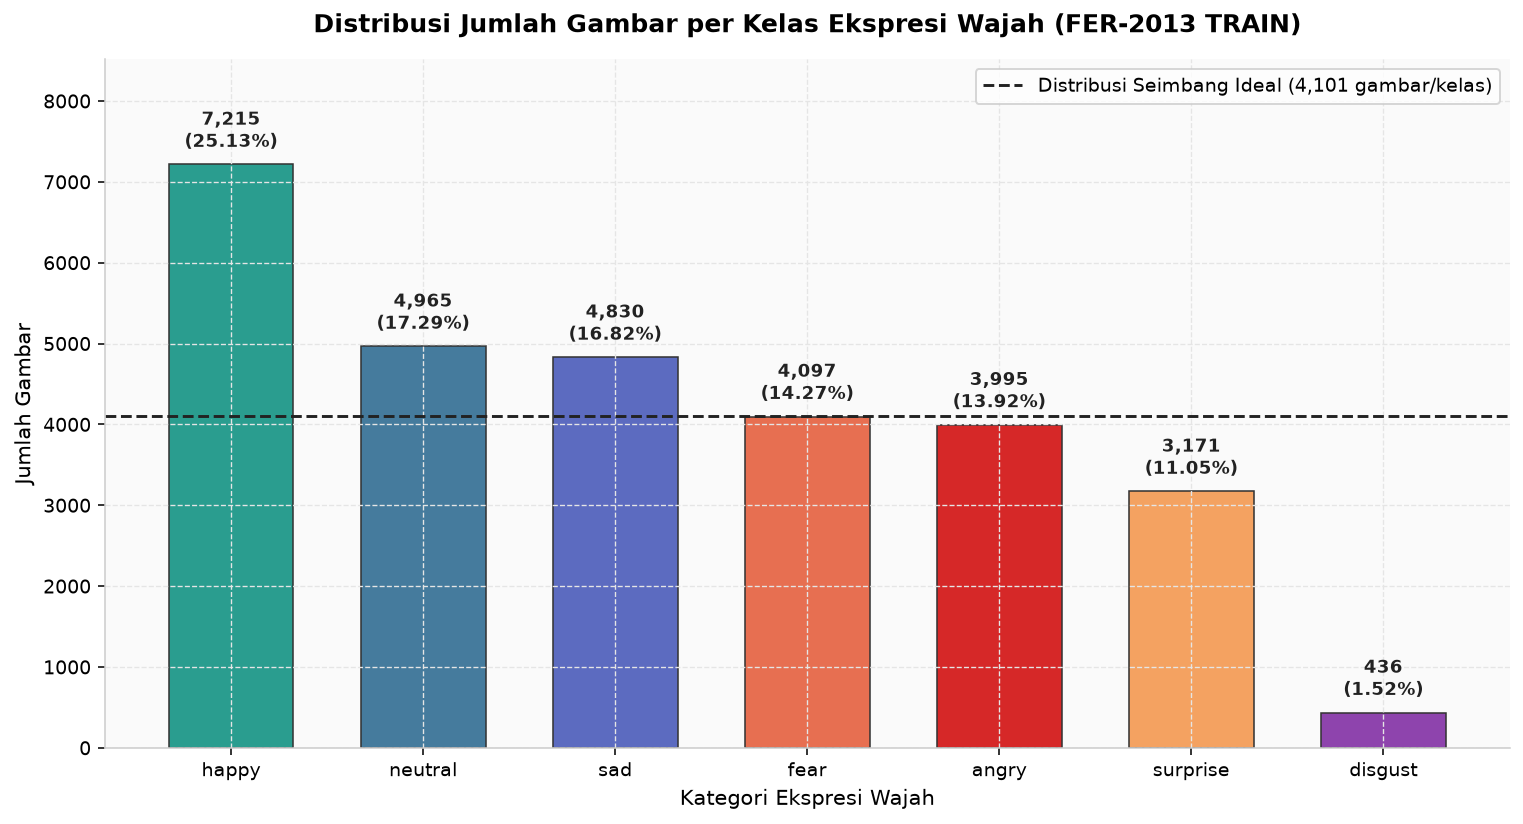

In [3]:
fig, ax = plt.subplots(figsize=(11, 6))

classes_sorted = train_dist_df["class"].tolist()
counts_sorted = train_dist_df["train_count"].tolist()
pcts_sorted = train_dist_df["train_pct"].tolist()
colors_sorted = [CLASS_COLORS[c] for c in classes_sorted]

bars = ax.bar(classes_sorted, counts_sorted, color=colors_sorted, edgecolor="#333333", linewidth=0.8, width=0.65)

ideal_count = train_total / len(classes_sorted)
ax.axhline(
    ideal_count,
    color="#222222",
    linestyle="--",
    linewidth=1.5,
    label=f"Distribusi Seimbang Ideal ({ideal_count:,.0f} gambar/kelas)",
)

for bar, count, pct in zip(bars, counts_sorted, pcts_sorted):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 140,
        f"{count:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color="#222222",
    )

ax.set_title("Distribusi Jumlah Gambar per Kelas Ekspresi Wajah (FER-2013 TRAIN)", pad=14)
ax.set_xlabel("Kategori Ekspresi Wajah")
ax.set_ylabel("Jumlah Gambar")
ax.set_ylim(0, max(counts_sorted) * 1.18)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
fig_path_01 = FIGURES_DIR / "01_train_class_distribution.png"
fig.savefig(fig_path_01, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {fig_path_01}")

### Analisis Visual Bar Chart Distribusi `TRAIN`
- Grafik memperlihatkan kesenjangan distribusi yang sangat jelas dibandingkan garis ideal **4.101 gambar/kelas**:
  - **Di atas garis ideal:** `happy` (7.215; +75,9%), `neutral` (4.965; +21,1%), dan `sad` (4.830; +17,8%).
  - **Mendekati garis ideal:** `fear` (4.097; -0,1%) dan `angry` (3.995; -2,6%).
  - **Di bawah garis ideal:** `surprise` (3.171; -22,7%) dan secara ekstrem **`disgust` (436; -89,4%)**.
- Pola ketimpangan ini mengonfirmasi bahwa model CNN berisiko bias ke kelas mayoritas (`happy`) dan memiliki *recall* rendah pada `disgust` apabila tidak ditangani secara khusus pada tahap pemodelan.

## 3. Contoh Citra Grayscale dari 7 Kelas (`TRAIN`)

Menampilkan **5 sampel acak deterministik** (`seed=42`) per kelas dari `data/raw/train/` (total 35 citra) pada skala abu-abu asli (`vmin=0, vmax=255`) untuk menilai kualitas visual, variasi pose, pencahayaan, dan tingkat kesulitan klasifikasi ekspresi pada resolusi 48 × 48.

Grafik disimpan ke: D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\outputs\figures\02_train_sample_images_7_classes.png


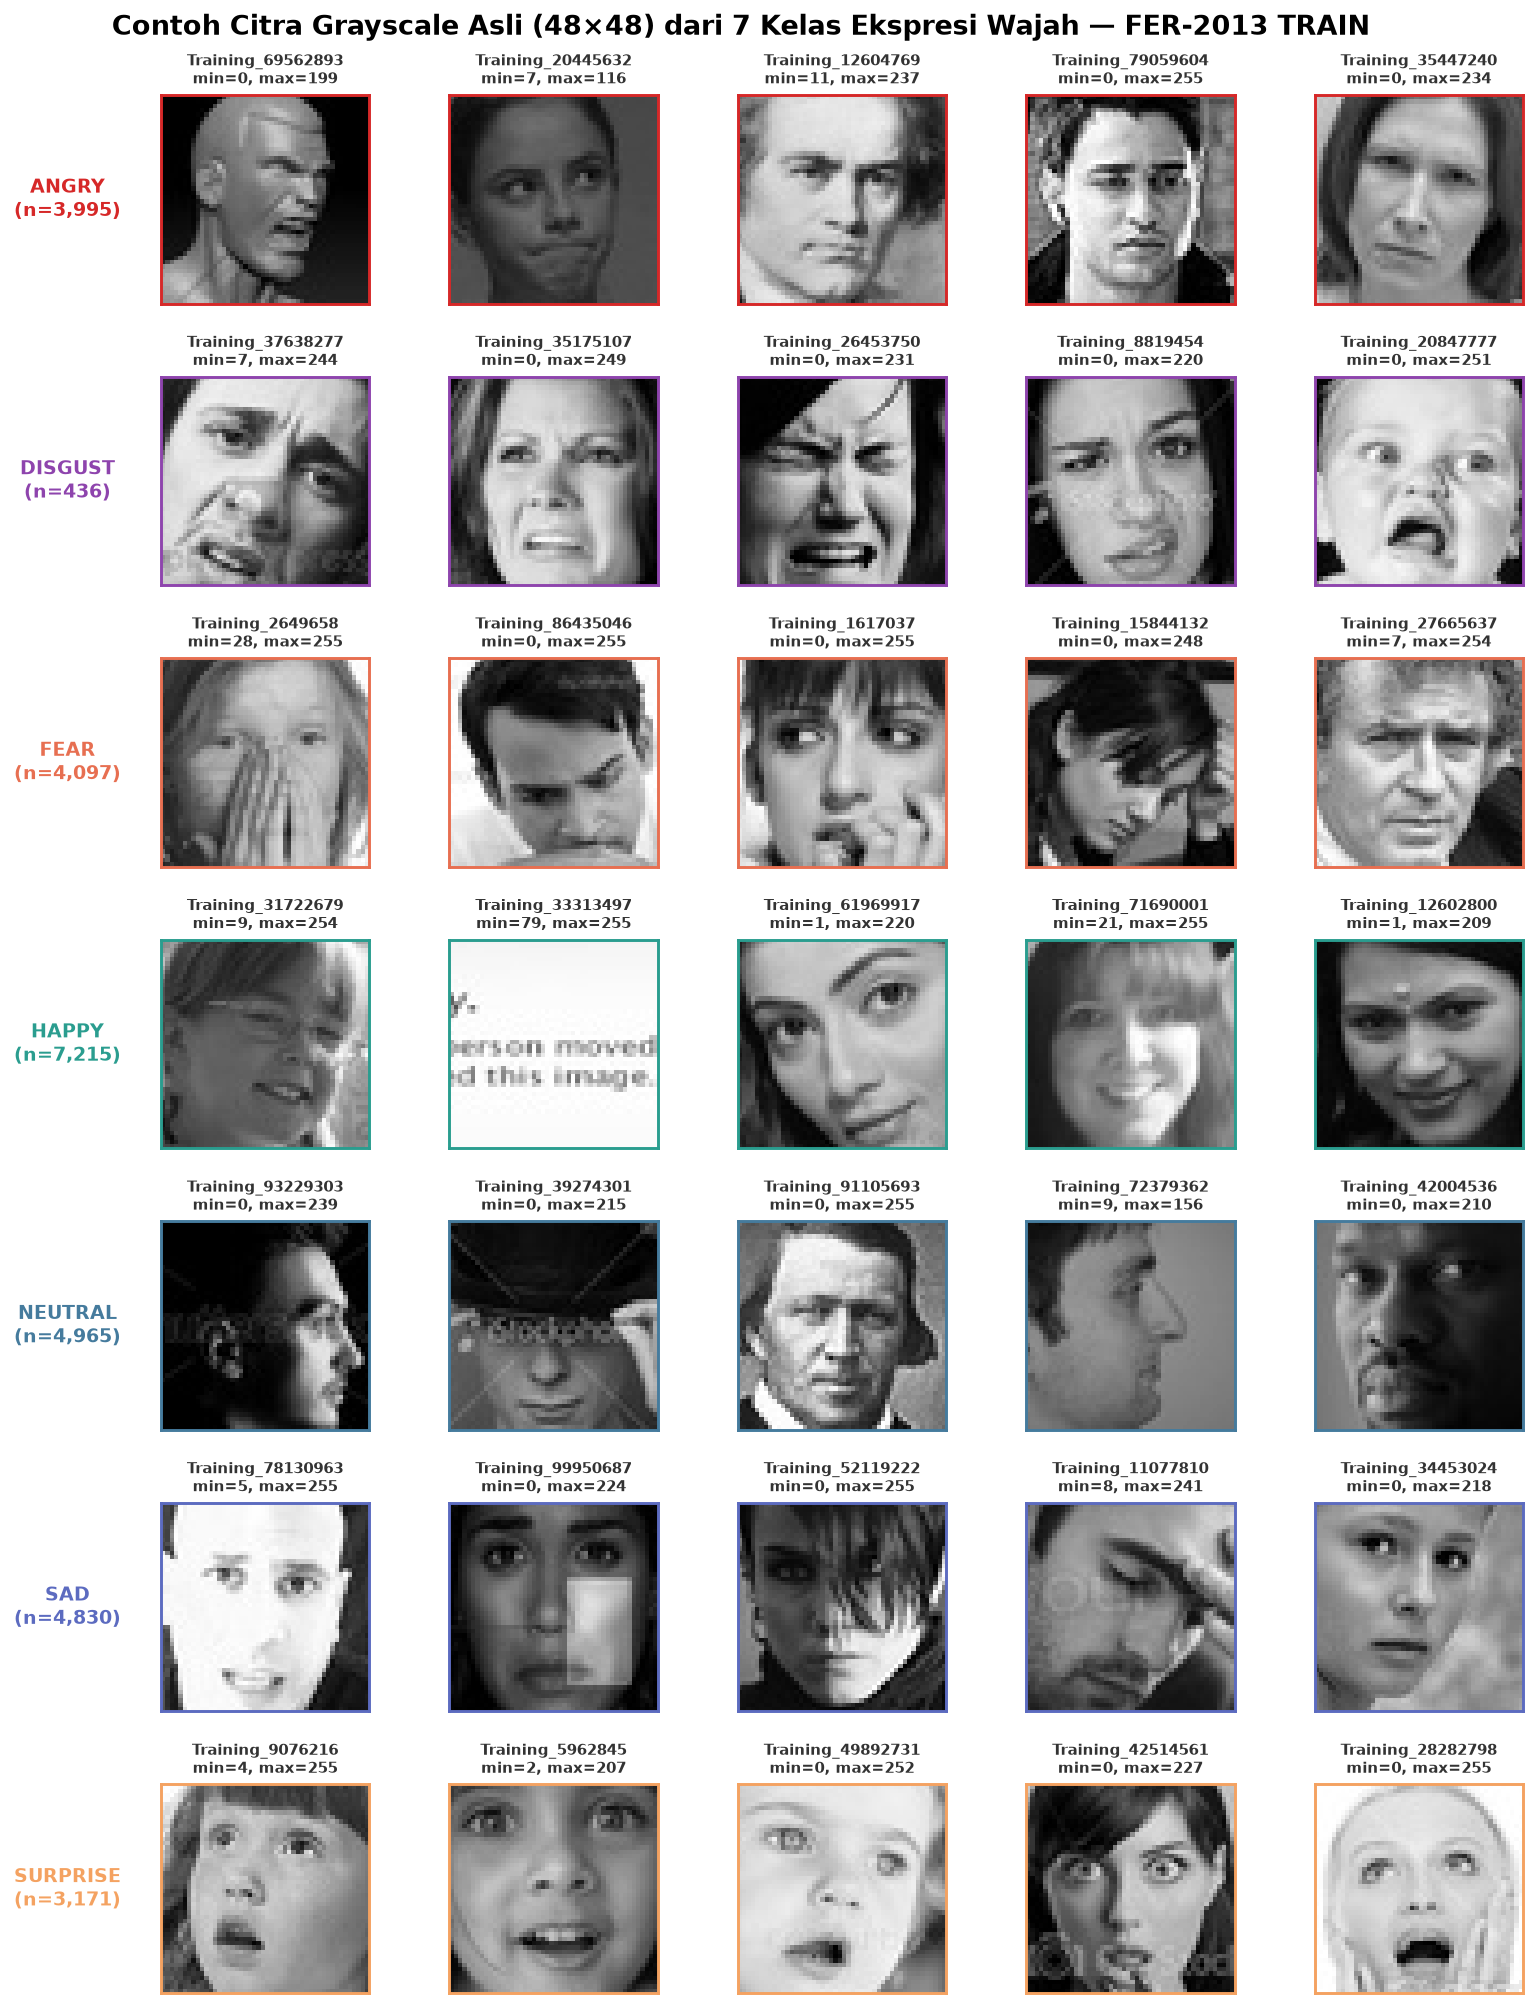

In [4]:
n_samples_per_class = 5
ordered_classes = sorted(train_categories)

fig, axes = plt.subplots(
    nrows=len(ordered_classes),
    ncols=n_samples_per_class,
    figsize=(12, 14.5),
    gridspec_kw={"wspace": 0.12, "hspace": 0.35},
)

rng = random.Random(RANDOM_SEED)

for row_idx, cls_name in enumerate(ordered_classes):
    files = train_file_map[cls_name]
    sampled_paths = rng.sample(files, n_samples_per_class)

    for col_idx, img_path in enumerate(sampled_paths):
        ax = axes[row_idx, col_idx]
        with Image.open(img_path) as img:
            arr = np.asarray(img, dtype=np.uint8)

        ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])

        # Border tipis berwarna kelas agar pemisahan antar baris jelas
        for spine in ax.spines.values():
            spine.set_edgecolor(CLASS_COLORS[cls_name])
            spine.set_linewidth(1.5)

        ax.set_title(f"{img_path.stem}\nmin={arr.min()}, max={arr.max()}", fontsize=7.5, color="#333333")

        if col_idx == 0:
            ax.set_ylabel(
                f"{cls_name.upper()}\n(n={train_counts[cls_name]:,})",
                fontsize=10,
                fontweight="bold",
                color=CLASS_COLORS[cls_name],
                rotation=0,
                labelpad=48,
                va="center",
            )

fig.suptitle(
    "Contoh Citra Grayscale Asli (48×48) dari 7 Kelas Ekspresi Wajah — FER-2013 TRAIN",
    fontsize=14,
    fontweight="bold",
    y=0.995,
)
plt.subplots_adjust(left=0.14, right=0.98, top=0.955, bottom=0.02)

fig_path_02 = FIGURES_DIR / "02_train_sample_images_7_classes.png"
fig.savefig(fig_path_02, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {fig_path_02}")

### Analisis Contoh Citra Grayscale (7 Kelas)
- **Karakteristik Visual Utama:** Seluruh citra berformat wajah *cropped* dalam skala abu-abu beresolusi rendah (`48×48` piksel), sehingga detail mikro wajah terbatas dan batas antar ekspresi tertentu (misalnya `fear` vs `surprise` atau `angry` vs `disgust` vs `sad`) cukup halus.
- **Variasi Kondisi Pengambilan Gambar:** Sampel aktual menunjukkan variasi besar pada pencahayaan (gelap hingga kontras tinggi), sudut/pose kepala (frontal hingga profil samping seperti `neutral/Training_72379362.jpg`), serta usia dan ekspresi subjek.
- **Temuan Noise Nyata pada Sampel Aktual FER-2013:**
  - **Citra non-wajah (*placeholder* teks):** `happy/Training_33313497.jpg` menampilkan teks *"person moved ... this image."* alih-alih wajah manusia.
  - **Watermark & non-foto:** Beberapa gambar mengandung *watermark* (mis. *iStockphoto* pada `neutral/Training_39274301.jpg`, `disgust/Training_8819454.jpg`, `surprise/Training_42514561.jpg`), render 3D/CGI (`angry/Training_69562893.jpg`), atau lukisan/ilustrasi (`angry/Training_12604769.jpg`, `neutral/Training_91105693.jpg`).
  - **Oklusi wajah:** Sebagian wajah tertutup tangan atau objek lain (mis. `fear/Training_2649658.jpg`).
- **Implikasi untuk Tahap Berikutnya:** Kehadiran *label/image noise*, oklusi, dan variasi pose menjelaskan mengapa akurasi manusia maupun model pada FER-2013 memiliki batas realistis tertentu, sekaligus memotivasi penerapan regularisasi dan augmentasi data moderat pada `TRAIN` saat tahap pemodelan.

## 4. Pemeriksaan Ukuran File, Dimensi, Mode Warna, dan Format Citra (`TRAIN`)

Pada sel berikut, seluruh **28.709 gambar pada `TRAIN`** dipindai secara penuh (100% *full scan*) dalam satu lintasan untuk mengumpulkan metadata citra sekaligus statistik piksel aktual (tanpa sampling/estimasi):
- Dimensi `(lebar, tinggi)`, mode warna (`L`, `RGB`, dll.), format aktual (`JPEG`, dll.), dan ekstensi file.
- Ukuran file dalam byte per gambar.
- Statistik piksel per gambar (`min`, `max`, `mean`, `std`), histogram global 0–255, serta deteksi citra piksel konstan (*blank/all-zero*).

In [5]:
records = []
global_pixel_hist = np.zeros(256, dtype=np.int64)
per_class_pixel_hist = {c: np.zeros(256, dtype=np.int64) for c in train_categories}
corrupted_train = []

for cls_name in train_categories:
    for fpath in train_file_map[cls_name]:
        fsize = fpath.stat().st_size
        ext = fpath.suffix.lower()
        try:
            with Image.open(fpath) as img:
                img.load()
                width, height = img.size
                mode = img.mode
                fmt = img.format
                arr = np.asarray(img, dtype=np.uint8)

            hist = np.bincount(arr.ravel(), minlength=256)
            global_pixel_hist += hist
            per_class_pixel_hist[cls_name] += hist

            pmin = int(arr.min())
            pmax = int(arr.max())
            pmean = float(arr.mean())
            pstd = float(arr.std())

            records.append({
                "class": cls_name,
                "filename": fpath.name,
                "extension": ext,
                "format": fmt,
                "mode": mode,
                "width": width,
                "height": height,
                "dimension": f"{width}x{height}",
                "file_size_bytes": fsize,
                "pixel_min": pmin,
                "pixel_max": pmax,
                "pixel_mean": pmean,
                "pixel_std": pstd,
                "is_constant": (pmin == pmax),
            })
        except Exception as exc:
            corrupted_train.append((str(fpath), f"{type(exc).__name__}: {exc}"))

train_meta_df = pd.DataFrame(records)

print(f"Total gambar TRAIN berhasil dipindai : {len(train_meta_df):,}")
print(f"Total gambar TRAIN rusak/gagal baca  : {len(corrupted_train)}")
print("\nRingkasan Dimensi, Mode, Format, dan Ekstensi (TRAIN):")
print("  Dimensi unik :", train_meta_df["dimension"].value_counts().to_dict())
print("  Mode warna   :", train_meta_df["mode"].value_counts().to_dict())
print("  Format aktual:", train_meta_df["format"].value_counts().to_dict())
print("  Ekstensi file:", train_meta_df["extension"].value_counts().to_dict())

filesize_by_class = (
    train_meta_df.groupby("class")["file_size_bytes"]
    .agg(count="count", min="min", q25=lambda s: s.quantile(0.25), median="median",
         mean="mean", q75=lambda s: s.quantile(0.75), max="max")
    .reindex(train_dist_df["class"])
    .round(2)
)
print("\nStatistik Ukuran File (Byte) per Kelas pada TRAIN:")
display(filesize_by_class)

Total gambar TRAIN berhasil dipindai : 28,709
Total gambar TRAIN rusak/gagal baca  : 0

Ringkasan Dimensi, Mode, Format, dan Ekstensi (TRAIN):
  Dimensi unik : {'48x48': 28709}
  Mode warna   : {'L': 28709}
  Format aktual: {'JPEG': 28709}
  Ekstensi file: {'.jpg': 28709}

Statistik Ukuran File (Byte) per Kelas pada TRAIN:


,count,min,q25,median,mean,q75,max
class,,,,,,,
happy,7215,359,1484.00,1580.0,1575.58,1671.00,2333
neutral,4965,359,1453.00,1556.0,1551.59,1652.00,2207
sad,4830,359,1440.00,1548.0,1546.69,1654.75,2294
fear,4097,568,1484.00,1595.0,1591.39,1698.00,2392
angry,3995,359,1477.00,1586.0,1582.30,1691.00,2364
surprise,3171,359,1523.00,1633.0,1618.37,1727.50,2302
disgust,436,931,1455.75,1538.0,1538.58,1628.25,2175


Grafik disimpan ke: D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\outputs\figures\03_train_dimensions_and_filesize.png


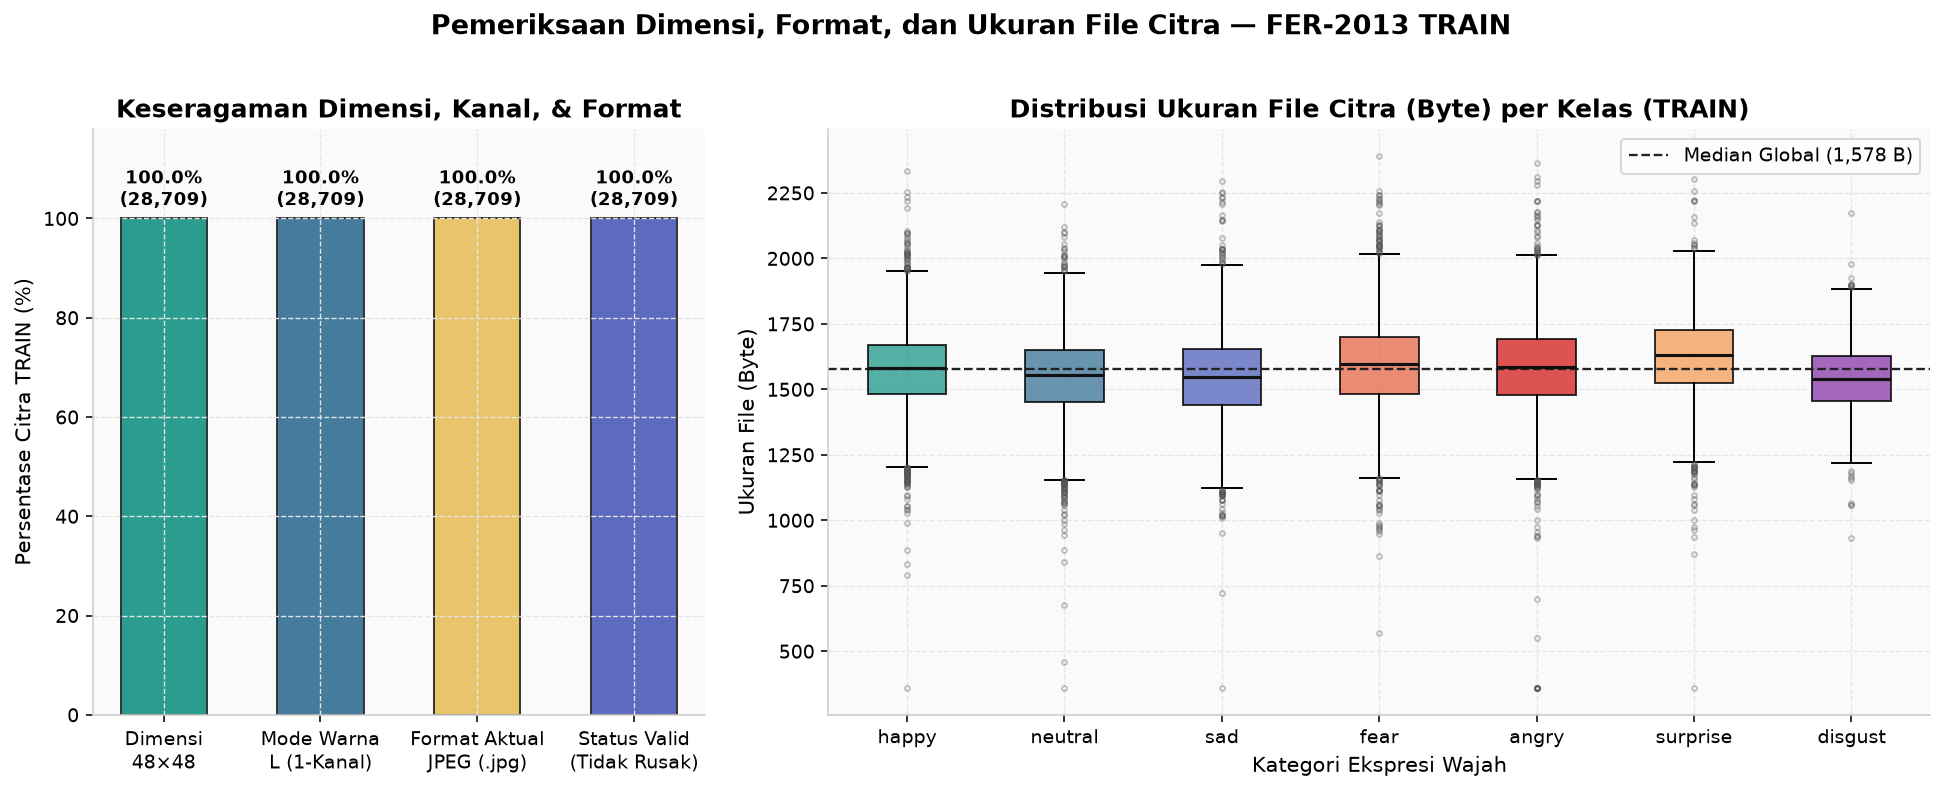

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.8]})

# Panel kiri: Ringkasan keseragaman properti teknis citra TRAIN
props = ["Dimensi\n48×48", "Mode Warna\nL (1-Kanal)", "Format Aktual\nJPEG (.jpg)", "Status Valid\n(Tidak Rusak)"]
pct_vals = [
    (train_meta_df["dimension"] == "48x48").mean() * 100,
    (train_meta_df["mode"] == "L").mean() * 100,
    (train_meta_df["format"] == "JPEG").mean() * 100,
    len(train_meta_df) / train_total * 100,
]
prop_colors = ["#2A9D8F", "#457B9D", "#E9C46A", "#5C6BC0"]

bars = axes[0].bar(props, pct_vals, color=prop_colors, edgecolor="#333333", width=0.55)
for bar, val in zip(bars, pct_vals):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        val + 1.5,
        f"{val:.1f}%\n({train_total:,})",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )
axes[0].set_ylim(0, 118)
axes[0].set_ylabel("Persentase Citra TRAIN (%)")
axes[0].set_title("Keseragaman Dimensi, Kanal, & Format")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Panel kanan: Distribusi ukuran file (byte) per kelas menggunakan boxplot
order_cls = train_dist_df["class"].tolist()
data_by_cls = [train_meta_df.loc[train_meta_df["class"] == c, "file_size_bytes"].values for c in order_cls]

bp = axes[1].boxplot(
    data_by_cls,
    tick_labels=order_cls,
    patch_artist=True,
    medianprops={"color": "#111111", "linewidth": 1.6},
    flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.35, "markeredgecolor": "#555555"},
)
for patch, cls_name in zip(bp["boxes"], order_cls):
    patch.set_facecolor(CLASS_COLORS[cls_name])
    patch.set_alpha(0.8)

axes[1].axhline(
    train_meta_df["file_size_bytes"].median(),
    color="#222222",
    linestyle="--",
    linewidth=1.2,
    label=f"Median Global ({train_meta_df['file_size_bytes'].median():,.0f} B)",
)
axes[1].set_title("Distribusi Ukuran File Citra (Byte) per Kelas (TRAIN)")
axes[1].set_xlabel("Kategori Ekspresi Wajah")
axes[1].set_ylabel("Ukuran File (Byte)")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(loc="upper right", frameon=True, facecolor="white")

fig.suptitle("Pemeriksaan Dimensi, Format, dan Ukuran File Citra — FER-2013 TRAIN", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path_03 = FIGURES_DIR / "03_train_dimensions_and_filesize.png"
fig.savefig(fig_path_03, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {fig_path_03}")

### Analisis Ukuran File, Dimensi, dan Format Citra (`TRAIN`)
- **Keseragaman Input 100%:** Seluruh **28.709 citra** pada `TRAIN` memiliki dimensi identik **48 × 48 piksel**, mode warna **`L` (Grayscale 8-bit, 1 kanal)**, dan format aktual **JPEG (`.jpg`)** tanpa satu pun citra rusak. Artinya, tensor input standar untuk arsitektur CNN kustom dapat langsung menggunakan bentuk `(48, 48, 1)` tanpa operasi *resizing* yang mendistorsi piksel.
- **Distribusi Ukuran File:** Ukuran file seluruh citra relatif kompak (berkisar antara **359 byte** hingga **2.392 byte**, median global **1.578 byte**, total ~43,09 MB), sehingga seluruh dataset `TRAIN` sangat efisien untuk dimuat ke memori saat eksperimen.
- **Outlier Ukuran File Kecil (~359 byte):** Titik *outlier* bawah pada boxplot bersesuaian dengan citra yang sangat seragam/minim detail, termasuk 11 citra hitam polos (*all-zero*) yang berukuran tepat 359 byte akibat kompresi JPEG.

## 5. Pemeriksaan Rentang & Distribusi Nilai Piksel (`TRAIN`)

Menganalisis rentang nilai piksel (`0`–`255`) dari seluruh **66.145.536 piksel** (`28.709 × 48 × 48`) pada `TRAIN`, mencakup:
1. Statistik global piksel (min, maks, mean, standar deviasi, median, kuartil, serta proporsi piksel ekstrem `0` dan `255`).
2. Distribusi rata-rata kecerahan (*mean brightness*) dan kontras (*pixel std*) per citra, termasuk identifikasi citra konstan (*zero-variance*).
3. Perbandingan distribusi kecerahan dan kontras antar 7 kelas untuk mendeteksi potensi bias pencahayaan.

In [7]:
pixel_values = np.arange(256, dtype=np.float64)
total_pixels = int(global_pixel_hist.sum())

global_mean = float((pixel_values * global_pixel_hist).sum() / total_pixels)
global_var = float((((pixel_values - global_mean) ** 2) * global_pixel_hist).sum() / total_pixels)
global_std = float(np.sqrt(global_var))

cum_pixels = np.cumsum(global_pixel_hist)
global_q25 = int(np.searchsorted(cum_pixels, total_pixels * 0.25))
global_median = int(np.searchsorted(cum_pixels, total_pixels * 0.50))
global_q75 = int(np.searchsorted(cum_pixels, total_pixels * 0.75))

pct_zero_pixels = global_pixel_hist[0] / total_pixels * 100
pct_255_pixels = global_pixel_hist[255] / total_pixels * 100

constant_imgs_df = train_meta_df[train_meta_df["is_constant"]].copy()

print("=== STATISTIK GLOBAL NILAI PIKSEL (FER-2013 TRAIN) ===")
print(f"Total piksel dianalisis     : {total_pixels:,} ({len(train_meta_df):,} × 48 × 48)")
print(f"Rentang nilai piksel aktual : {int(train_meta_df['pixel_min'].min())} – {int(train_meta_df['pixel_max'].max())} (uint8)")
print(f"Mean global                 : {global_mean:.4f} (skala [0,1]: {global_mean / 255:.4f})")
print(f"Std global                  : {global_std:.4f} (skala [0,1]: {global_std / 255:.4f})")
print(f"Kuartil (Q25 / Median / Q75): {global_q25} / {global_median} / {global_q75}")
print(f"Proporsi piksel = 0 (hitam) : {pct_zero_pixels:.2f}% ({global_pixel_hist[0]:,} piksel)")
print(f"Proporsi piksel = 255 (putih): {pct_255_pixels:.2f}% ({global_pixel_hist[255]:,} piksel)")
print(f"Jumlah citra piksel konstan : {len(constant_imgs_df)} gambar")

if len(constant_imgs_df) > 0:
    print("\nDaftar citra piksel konstan (hitam polos) di TRAIN:")
    display(constant_imgs_df[["class", "filename", "file_size_bytes", "pixel_min", "pixel_max", "pixel_std"]])

# Ringkasan statistik piksel per kelas
class_pixel_rows = []
for cls_name in train_dist_df["class"]:
    h = per_class_pixel_hist[cls_name]
    n_px = int(h.sum())
    c_mean = float((pixel_values * h).sum() / n_px)
    c_std = float(np.sqrt((((pixel_values - c_mean) ** 2) * h).sum() / n_px))
    c_cum = np.cumsum(h)
    c_med = int(np.searchsorted(c_cum, n_px * 0.50))
    sub = train_meta_df[train_meta_df["class"] == cls_name]
    class_pixel_rows.append({
        "class": cls_name,
        "pixel_min": int(sub["pixel_min"].min()),
        "pixel_max": int(sub["pixel_max"].max()),
        "pixel_mean": round(c_mean, 2),
        "pixel_std": round(c_std, 2),
        "pixel_median": c_med,
        "img_mean_brightness_med": round(float(sub["pixel_mean"].median()), 2),
        "img_contrast_std_med": round(float(sub["pixel_std"].median()), 2),
        "constant_images": int(sub["is_constant"].sum()),
    })

class_pixel_df = pd.DataFrame(class_pixel_rows)
print("\n=== STATISTIK NILAI PIKSEL PER KELAS (TRAIN) ===")
display(class_pixel_df)

=== STATISTIK GLOBAL NILAI PIKSEL (FER-2013 TRAIN) ===
Total piksel dianalisis     : 66,145,536 (28,709 × 48 × 48)
Rentang nilai piksel aktual : 0 – 255 (uint8)
Mean global                 : 129.4733 (skala [0,1]: 0.5077)
Std global                  : 65.0448 (skala [0,1]: 0.2551)
Kuartil (Q25 / Median / Q75): 79 / 134 / 181
Proporsi piksel = 0 (hitam) : 0.64% (425,994 piksel)
Proporsi piksel = 255 (putih): 0.82% (541,975 piksel)
Jumlah citra piksel konstan : 11 gambar

Daftar citra piksel konstan (hitam polos) di TRAIN:

=== STATISTIK NILAI PIKSEL PER KELAS (TRAIN) ===


,class,filename,file_size_bytes,pixel_min,pixel_max,pixel_std
2,angry,Training_10131352.jpg,359,0,0,0.0
838,angry,Training_28756096.jpg,359,0,0,0.0
1002,angry,Training_32571770.jpg,359,0,0,0.0
1882,angry,Training_52563817.jpg,359,0,0,0.0
3006,angry,Training_78540321.jpg,359,0,0,0.0
3846,angry,Training_96772745.jpg,359,0,0,0.0
3965,angry,Training_99531165.jpg,359,0,0,0.0
14749,happy,Training_87607167.jpg,359,0,0,0.0
20112,neutral,Training_89335926.jpg,359,0,0,0.0
22795,sad,Training_48621797.jpg,359,0,0,0.0


,class,pixel_min,pixel_max,pixel_mean,pixel_std,pixel_median,img_mean_brightness_med,img_contrast_std_med,constant_images
0,happy,0,255,129.43,63.38,134,127.92,52.60,1
1,neutral,0,255,123.90,65.30,126,123.59,54.37,1
2,sad,0,255,121.28,64.87,124,121.23,52.90,1
3,fear,0,255,135.52,65.00,142,136.89,54.20,0
4,angry,0,255,126.23,65.19,130,127.16,53.97,7
5,surprise,0,255,146.26,64.93,157,148.70,55.34,1
6,disgust,0,255,135.23,63.41,141,132.70,50.23,0


Grafik disimpan ke: D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\outputs\figures\04_train_pixel_intensity_distribution.png


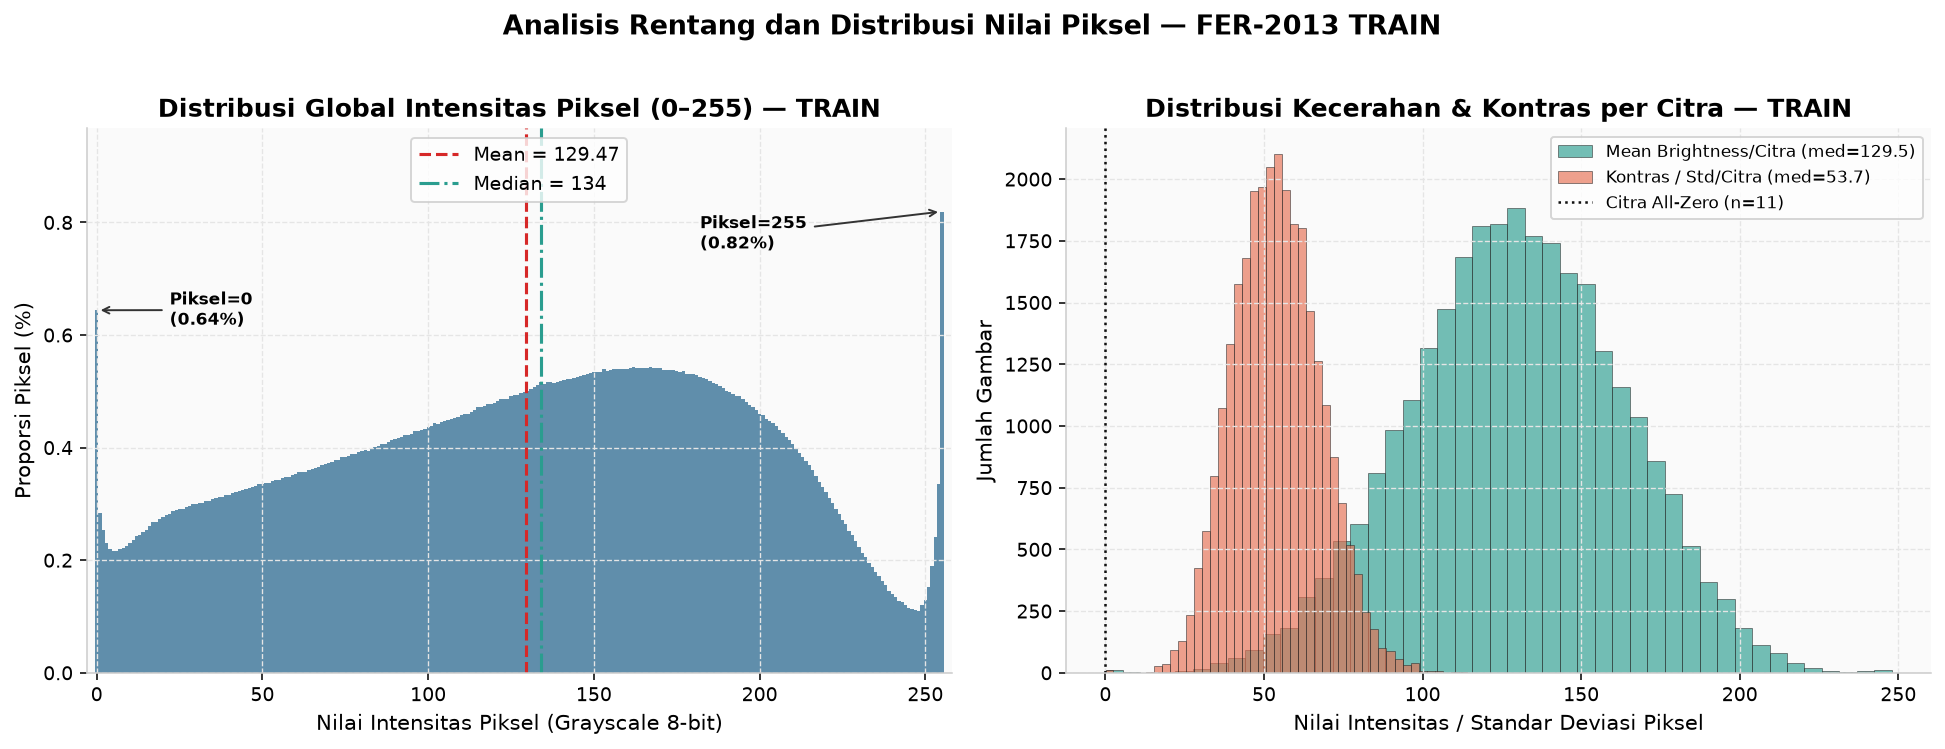

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel kiri: Histogram intensitas piksel global (0-255)
axes[0].bar(
    pixel_values,
    global_pixel_hist / total_pixels * 100,
    width=1.0,
    color="#457B9D",
    alpha=0.85,
    edgecolor="none",
)
axes[0].axvline(global_mean, color="#D62828", linestyle="--", linewidth=1.6, label=f"Mean = {global_mean:.2f}")
axes[0].axvline(global_median, color="#2A9D8F", linestyle="-.", linewidth=1.6, label=f"Median = {global_median}")
axes[0].set_xlim(-3, 258)
axes[0].set_ylim(0, max(pct_zero_pixels, pct_255_pixels) * 1.18)
axes[0].set_title("Distribusi Global Intensitas Piksel (0–255) — TRAIN")
axes[0].set_xlabel("Nilai Intensitas Piksel (Grayscale 8-bit)")
axes[0].set_ylabel("Proporsi Piksel (%)")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(loc="upper center", frameon=True, facecolor="white")

# Anotasi lonjakan pada nilai batas 0 dan 255 (rapi di dalam area plot)
axes[0].annotate(
    f"Piksel=0\n({pct_zero_pixels:.2f}%)",
    xy=(0, pct_zero_pixels),
    xytext=(22, pct_zero_pixels * 0.96),
    arrowprops={"arrowstyle": "->", "color": "#333333", "lw": 1.0},
    fontsize=8.5,
    fontweight="bold",
)
axes[0].annotate(
    f"Piksel=255\n({pct_255_pixels:.2f}%)",
    xy=(255, pct_255_pixels),
    xytext=(182, pct_255_pixels * 0.92),
    arrowprops={"arrowstyle": "->", "color": "#333333", "lw": 1.0},
    fontsize=8.5,
    fontweight="bold",
)

# Panel kanan: Distribusi Mean Brightness dan Contrast (Std) per gambar
axes[1].hist(
    train_meta_df["pixel_mean"],
    bins=45,
    color="#2A9D8F",
    alpha=0.65,
    edgecolor="#222222",
    linewidth=0.4,
    label=f"Mean Brightness/Citra (med={train_meta_df['pixel_mean'].median():.1f})",
)
axes[1].hist(
    train_meta_df["pixel_std"],
    bins=45,
    color="#E76F51",
    alpha=0.65,
    edgecolor="#222222",
    linewidth=0.4,
    label=f"Kontras / Std/Citra (med={train_meta_df['pixel_std'].median():.1f})",
)
axes[1].axvline(0, color="#111111", linestyle=":", linewidth=1.3, label=f"Citra All-Zero (n={len(constant_imgs_df)})")
axes[1].set_title("Distribusi Kecerahan & Kontras per Citra — TRAIN")
axes[1].set_xlabel("Nilai Intensitas / Standar Deviasi Piksel")
axes[1].set_ylabel("Jumlah Gambar")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(loc="upper right", frameon=True, facecolor="white", fontsize=8.8)

fig.suptitle("Analisis Rentang dan Distribusi Nilai Piksel — FER-2013 TRAIN", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path_04 = FIGURES_DIR / "04_train_pixel_intensity_distribution.png"
fig.savefig(fig_path_04, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {fig_path_04}")

Grafik disimpan ke: D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\outputs\figures\05_train_pixel_stats_by_class.png


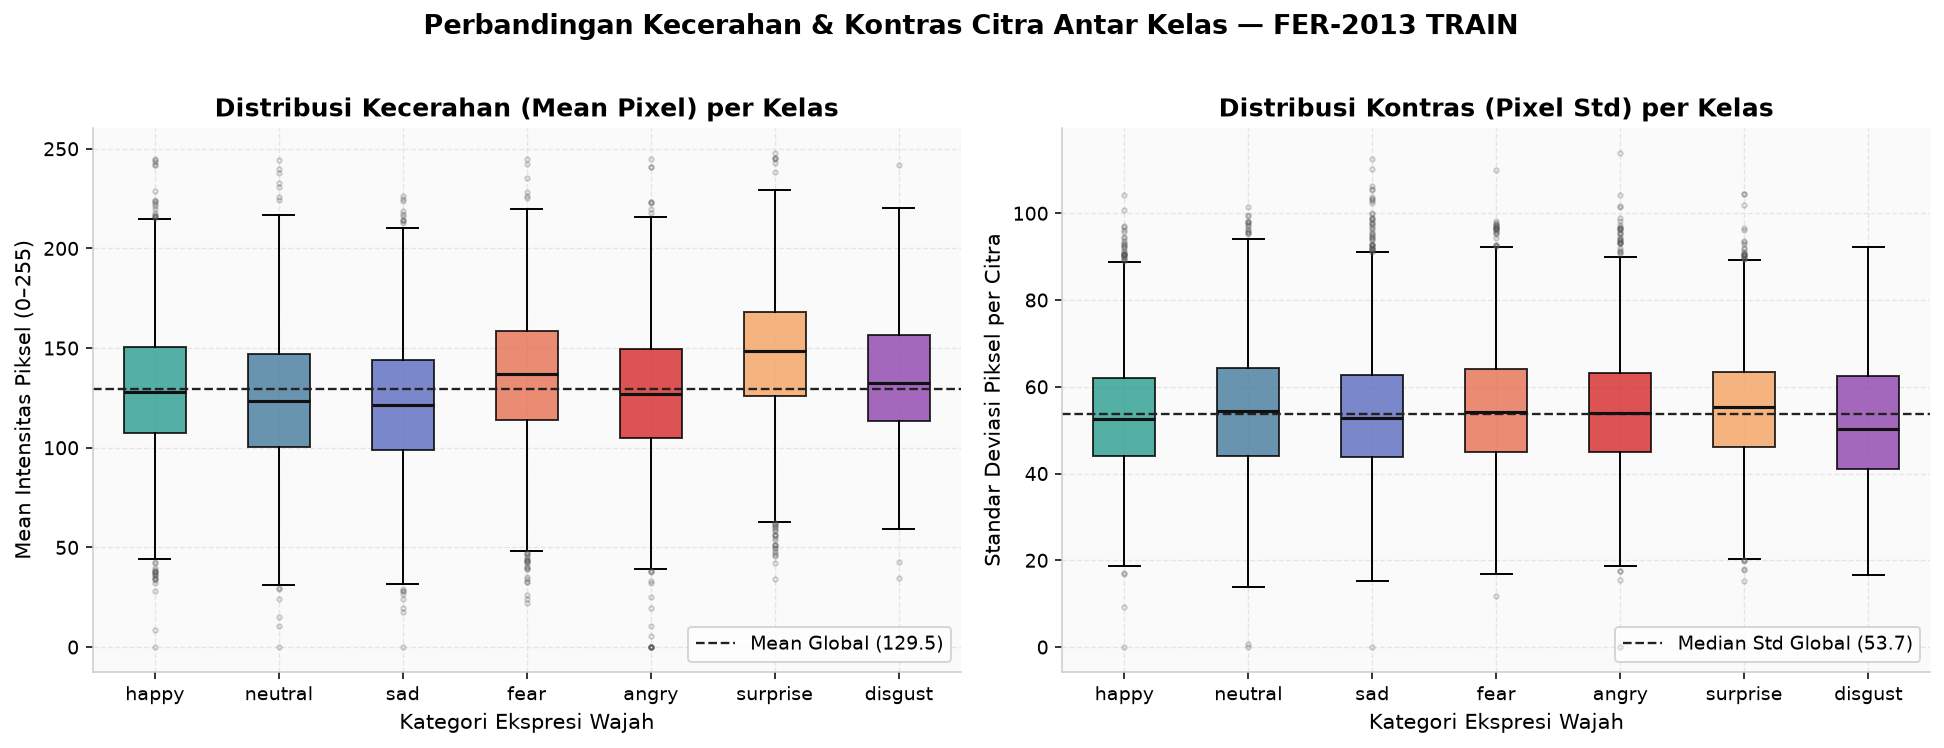

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
order_cls = train_dist_df["class"].tolist()

# Panel kiri: Boxplot rata-rata kecerahan citra per kelas
brightness_data = [train_meta_df.loc[train_meta_df["class"] == c, "pixel_mean"].values for c in order_cls]
bp1 = axes[0].boxplot(
    brightness_data,
    tick_labels=order_cls,
    patch_artist=True,
    medianprops={"color": "#111111", "linewidth": 1.6},
    flierprops={"marker": "o", "markersize": 2.2, "alpha": 0.3, "markeredgecolor": "#555555"},
)
for patch, cls_name in zip(bp1["boxes"], order_cls):
    patch.set_facecolor(CLASS_COLORS[cls_name])
    patch.set_alpha(0.8)

axes[0].axhline(global_mean, color="#222222", linestyle="--", linewidth=1.2, label=f"Mean Global ({global_mean:.1f})")
axes[0].set_title("Distribusi Kecerahan (Mean Pixel) per Kelas")
axes[0].set_xlabel("Kategori Ekspresi Wajah")
axes[0].set_ylabel("Mean Intensitas Piksel (0–255)")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].legend(loc="lower right", frameon=True, facecolor="white")

# Panel kanan: Boxplot kontras (std pixel) per kelas
contrast_data = [train_meta_df.loc[train_meta_df["class"] == c, "pixel_std"].values for c in order_cls]
bp2 = axes[1].boxplot(
    contrast_data,
    tick_labels=order_cls,
    patch_artist=True,
    medianprops={"color": "#111111", "linewidth": 1.6},
    flierprops={"marker": "o", "markersize": 2.2, "alpha": 0.3, "markeredgecolor": "#555555"},
)
for patch, cls_name in zip(bp2["boxes"], order_cls):
    patch.set_facecolor(CLASS_COLORS[cls_name])
    patch.set_alpha(0.8)

axes[1].axhline(train_meta_df["pixel_std"].median(), color="#222222", linestyle="--", linewidth=1.2,
                label=f"Median Std Global ({train_meta_df['pixel_std'].median():.1f})")
axes[1].set_title("Distribusi Kontras (Pixel Std) per Kelas")
axes[1].set_xlabel("Kategori Ekspresi Wajah")
axes[1].set_ylabel("Standar Deviasi Piksel per Citra")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(loc="lower right", frameon=True, facecolor="white")

fig.suptitle("Perbandingan Kecerahan & Kontras Citra Antar Kelas — FER-2013 TRAIN", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path_05 = FIGURES_DIR / "05_train_pixel_stats_by_class.png"
fig.savefig(fig_path_05, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {fig_path_05}")

### Analisis Rentang & Distribusi Nilai Piksel (`TRAIN`)
- **Rentang & Parameter Normalisasi Global (`TRAIN`):** Seluruh **66.145.536 piksel** menempati rentang penuh 8-bit **`0` – `255`** dengan **mean = `129,4733`** (`0,5077` pada skala `[0, 1]`), **standar deviasi = `65,0448`** (`0,2551` pada skala `[0, 1]`), dan kuartil **Q25 = 79 | Median = 134 | Q75 = 181**. Parameter ini kelak dapat digunakan untuk rescaling `[0, 1]` atau standardisasi *(z-score)* yang di-*fit* murni pada data latih.
- **Lonjakan Nilai Batas (*Boundary Clipping*):** Terlihat lonjakan tajam tepat pada piksel **`0` (0,64% / 425.994 piksel)** dan **`255` (0,82% / 541.975 piksel)** yang berasal dari area saturasi pencahayaan/latar hitam-putih serta citra hitam polos.
- **Deteksi Citra Tanpa Informasi Visual:** Ditemukan **11 citra piksel konstan (`all-zero`, `std = 0`)** di `TRAIN`—didominasi oleh kelas `angry` (7 gambar) serta masing-masing 1 gambar pada `happy`, `neutral`, `sad`, dan `surprise`. Seluruhnya berukuran 359 byte dan tidak mengandung fitur wajah apa pun.
- **Perbedaan Kecerahan Antar Kelas:** Kelas `surprise` memiliki kecerahan rata-rata paling tinggi (`pixel_mean = 146,26`, median citra `148,70`), sedangkan `sad` paling gelap (`pixel_mean = 121,28`, median citra `121,23`)—selisih sekitar **25 level intensitas**. Sebaliknya, median kontras (`pixel_std` per citra) relatif seragam di kisaran `50,23` (`disgust`) hingga `55,34` (`surprise`). Perbedaan kecerahan antar kelas ini penting diperhatikan agar model CNN tidak mengandalkan kecerahan latar sebagai jalan pintas klasifikasi (augmentasi kecerahan/kontras ringan pada `TRAIN` dapat membantu mitigasi).

## 6. Analisis Ketidakseimbangan Kelas (*Class Imbalance*) pada `TRAIN`

Mengukur keparahan ketidakseimbangan kelas pada `TRAIN` menggunakan beberapa metrik kuantitatif:
- Rasio terhadap kelas mayoritas (`happy / kelas`) dan rasio terhadap kelas minoritas (`kelas / disgust`).
- Deviasi persentase dari jumlah ideal seimbang (`4.101,29` gambar/kelas).
- Bobot kelas invers-frekuensi (*balanced class weight* diagnostik: $w_c = N / (K \cdot n_c)$) sebagai indikator seberapa besar penalti proporsional yang diperlukan untuk menyeimbangkan kontribusi gradien antar kelas.
- Metrik agregat keseimbangan distribusi: **Normalized Shannon Entropy** ($H / \log_2 7$, di mana $1.0$ = seimbang sempurna) dan **Gini Coefficient** ($0.0$ = seimbang sempurna).

In [10]:
n_classes = len(train_dist_df)
ideal_per_class = train_total / n_classes
max_count = int(train_dist_df["train_count"].max())
min_count = int(train_dist_df["train_count"].min())

imbalance_df = train_dist_df[["class", "train_count", "train_pct"]].copy()
imbalance_df["deviation_from_ideal"] = (imbalance_df["train_count"] - ideal_per_class).round(1)
imbalance_df["deviation_pct"] = ((imbalance_df["train_count"] - ideal_per_class) / ideal_per_class * 100).round(2)
imbalance_df["ratio_vs_min_class"] = (imbalance_df["train_count"] / min_count).round(2)
imbalance_df["ratio_max_to_class"] = (max_count / imbalance_df["train_count"]).round(2)
imbalance_df["balanced_class_weight"] = (train_total / (n_classes * imbalance_df["train_count"])).round(3)

# Metrik ketidakseimbangan agregat
probs = imbalance_df["train_count"].values / train_total
shannon_entropy = float(-np.sum(probs * np.log2(probs)))
max_entropy = float(np.log2(n_classes))
normalized_entropy = shannon_entropy / max_entropy

sorted_counts = np.sort(imbalance_df["train_count"].values)
idx = np.arange(1, n_classes + 1)
gini_coeff = float(np.sum((2 * idx - n_classes - 1) * sorted_counts) / (n_classes * np.sum(sorted_counts)))

print("=== METRIK KETIDAKSEIMBANGAN KELAS (TRAIN) ===")
print(f"Kelas mayoritas                  : {imbalance_df.iloc[0]['class']} ({max_count:,} gambar, {imbalance_df.iloc[0]['train_pct']:.2f}%)")
print(f"Kelas minoritas                  : {imbalance_df.iloc[-1]['class']} ({min_count:,} gambar, {imbalance_df.iloc[-1]['train_pct']:.2f}%)")
print(f"Imbalance Ratio (Max / Min)      : {max_count / min_count:.2f} : 1")
print(f"Shannon Entropy / Max Entropy    : {shannon_entropy:.4f} / {max_entropy:.4f} (Normalized = {normalized_entropy:.4f})")
print(f"Gini Coefficient (0=seimbang)    : {gini_coeff:.4f}")
print(f"Naive Majority-Class Accuracy    : {max_count / train_total * 100:.2f}% (Macro F1 ≈ {2 * (max_count / train_total) / (1 + max_count / train_total) / n_classes * 100:.2f}%)")

display(imbalance_df)

=== METRIK KETIDAKSEIMBANGAN KELAS (TRAIN) ===
Kelas mayoritas                  : happy (7,215 gambar, 25.13%)
Kelas minoritas                  : disgust (436 gambar, 1.52%)
Imbalance Ratio (Max / Min)      : 16.55 : 1
Shannon Entropy / Max Entropy    : 2.6108 / 2.8074 (Normalized = 0.9300)
Gini Coefficient (0=seimbang)    : 0.2464
Naive Majority-Class Accuracy    : 25.13% (Macro F1 ≈ 5.74%)


,class,train_count,train_pct,deviation_from_ideal,deviation_pct,ratio_vs_min_class,ratio_max_to_class,balanced_class_weight
0,happy,7215,25.13,3113.7,75.92,16.55,1.00,0.568
1,neutral,4965,17.29,863.7,21.06,11.39,1.45,0.826
2,sad,4830,16.82,728.7,17.77,11.08,1.49,0.849
3,fear,4097,14.27,-4.3,-0.10,9.40,1.76,1.001
4,angry,3995,13.92,-106.3,-2.59,9.16,1.81,1.027
5,surprise,3171,11.05,-930.3,-22.68,7.27,2.28,1.293
6,disgust,436,1.52,-3665.3,-89.37,1.00,16.55,9.407


Grafik disimpan ke: D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\outputs\figures\06_train_class_imbalance_analysis.png


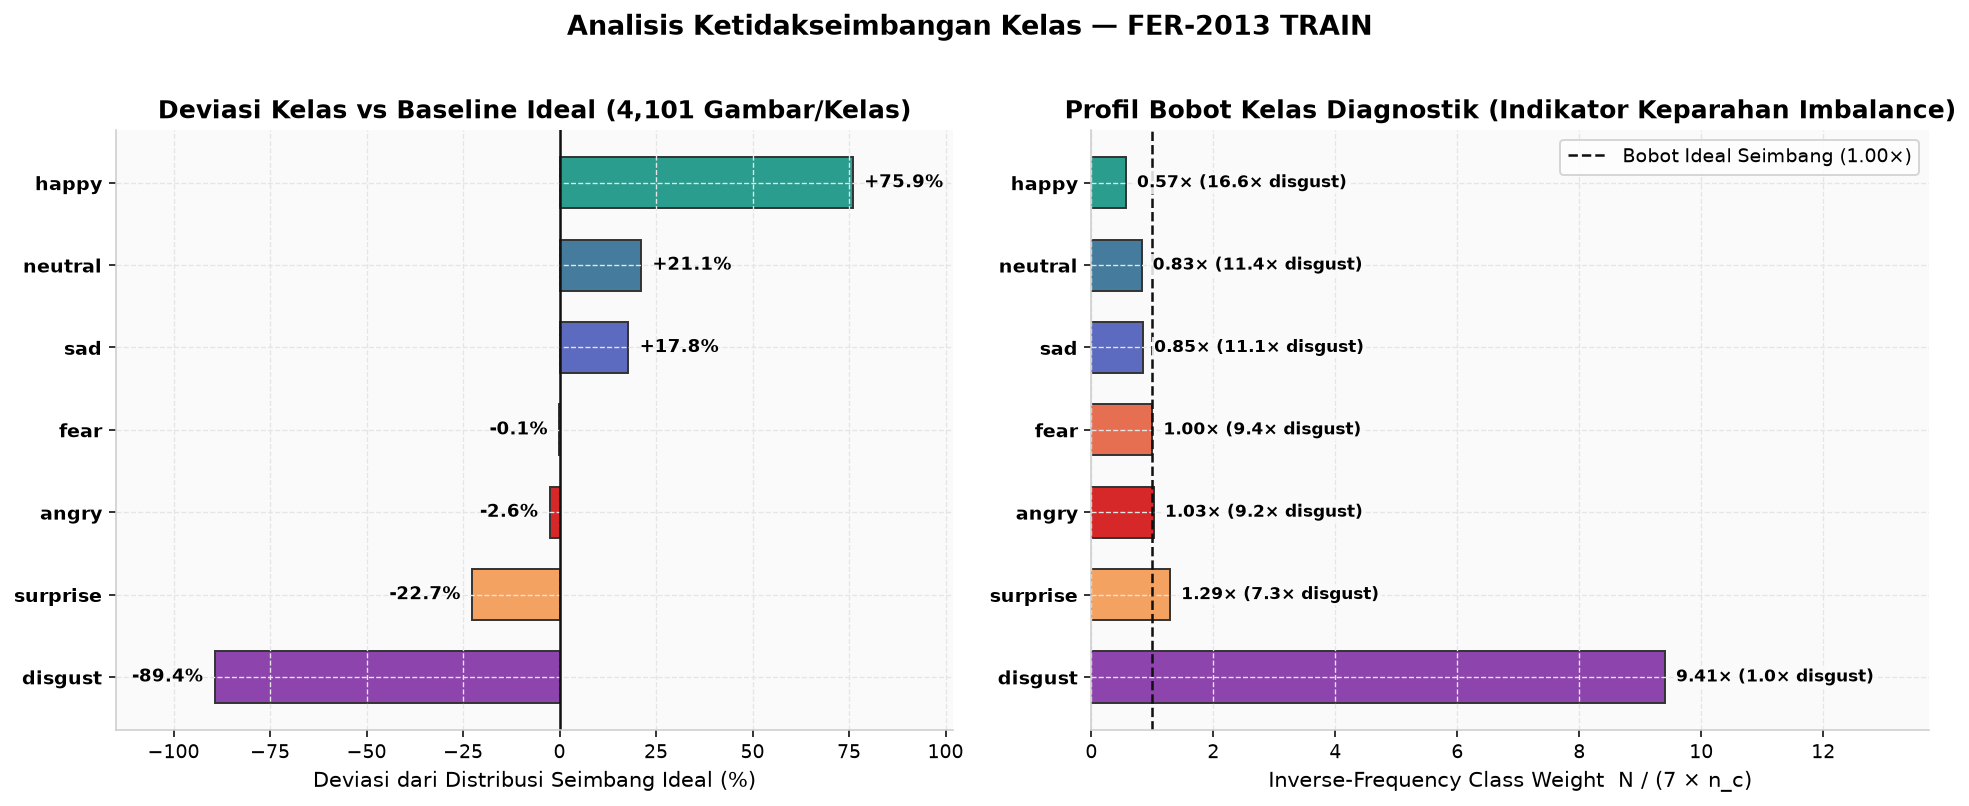

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

plot_df = imbalance_df.iloc[::-1].reset_index(drop=True)  # Urutkan dari terkecil (bawah) ke terbesar (atas)
y_pos = np.arange(len(plot_df))
bar_colors = [CLASS_COLORS[c] for c in plot_df["class"]]

# Panel kiri: Deviasi persentase dari jumlah ideal seimbang (4.101 gambar/kelas)
bars_left = axes[0].barh(y_pos, plot_df["deviation_pct"], color=bar_colors, edgecolor="#333333", height=0.62)
axes[0].axvline(0, color="#111111", linewidth=1.3)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_df["class"], fontweight="bold")
axes[0].set_xlabel("Deviasi dari Distribusi Seimbang Ideal (%)")
axes[0].set_title(f"Deviasi Kelas vs Baseline Ideal ({ideal_per_class:,.0f} Gambar/Kelas)")
axes[0].set_xlim(-115, 102)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

for bar, dev_pct in zip(bars_left, plot_df["deviation_pct"]):
    offset = 3 if dev_pct >= 0 else -3
    ha = "left" if dev_pct >= 0 else "right"
    axes[0].text(
        dev_pct + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{dev_pct:+.1f}%",
        va="center",
        ha=ha,
        fontsize=9,
        fontweight="bold",
    )

# Panel kanan: Profil Balanced Class Weight (N / (K * n_c)) sebagai indikator keparahan imbalance
bars_right = axes[1].barh(y_pos, plot_df["balanced_class_weight"], color=bar_colors, edgecolor="#333333", height=0.62)
axes[1].axvline(1.0, color="#111111", linestyle="--", linewidth=1.3, label="Bobot Ideal Seimbang (1.00×)")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(plot_df["class"], fontweight="bold")
axes[1].set_xlabel("Inverse-Frequency Class Weight  N / (7 × n_c)")
axes[1].set_title("Profil Bobot Kelas Diagnostik (Indikator Keparahan Imbalance)")
axes[1].set_xlim(0, plot_df["balanced_class_weight"].max() * 1.46)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].legend(loc="upper right", frameon=True, facecolor="white")

for bar, w, r in zip(bars_right, plot_df["balanced_class_weight"], plot_df["ratio_vs_min_class"]):
    axes[1].text(
        w + 0.18,
        bar.get_y() + bar.get_height() / 2,
        f"{w:.2f}× ({r:.1f}× disgust)",
        va="center",
        ha="left",
        fontsize=8.6,
        fontweight="bold",
        bbox={"facecolor": "#FAFAFA", "alpha": 0.85, "edgecolor": "none", "pad": 1.2},
    )

fig.suptitle("Analisis Ketidakseimbangan Kelas — FER-2013 TRAIN", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path_06 = FIGURES_DIR / "06_train_class_imbalance_analysis.png"
fig.savefig(fig_path_06, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {fig_path_06}")

### Analisis Ketidakseimbangan Kelas (`TRAIN`)
- **Keparahan Imbalance:** Dataset `TRAIN` memiliki rasio ketimpangan ekstrem **16,55 : 1** antara kelas mayoritas `happy` (7.215 gambar; +75,92% di atas ideal) dan kelas minoritas `disgust` (436 gambar; -89,37% di bawah ideal). Keenam kelas lainnya berjumlah 7,3× hingga 16,6× lebih banyak dibandingkan `disgust`.
- **Metrik Keseimbangan Agregat:** Nilai *Normalized Shannon Entropy* sebesar **0,9300** (`2,6108 / 2,8074` bit) dan *Gini Coefficient* sebesar **0,2464** menunjukkan bahwa enam kelas non-`disgust` cukup moderat persebarannya, namun satu kelas minoritas ekstrem (`disgust`) menciptakan ketimpangan berat pada ekor distribusi.
- **Bobot Kelas Diagnostik:** Jika menggunakan skema *inverse-frequency class weighting* ($N / (7 \cdot n_c)$), `disgust` memiliki bobot **9,407×** sedangkan `happy` hanya **0,568×**.
- **Risiko Evaluasi Naive:** Prediktor naif yang selalu menebak kelas mayoritas (`happy`) akan memperoleh *accuracy* **25,13%**, namun *Macro F1-Score*-nya hanya **~5,74%**. Oleh karena itu, metrik evaluasi utama pada tahap pemodelan kelak harus mencakup **Macro F1-Score**, **Precision/Recall per kelas** (khususnya `disgust`), dan **Confusion Matrix**.

## 7. Ringkasan Karakteristik Dataset

Menyajikan tabel ringkasan menyeluruh yang menggabungkan karakteristik utama `TRAIN` (hasil analisis penuh) serta status verifikasi struktur `TEST` (*read-only*, tanpa kebocoran konfigurasi).

In [12]:
summary_rows = [
    ("Nama Dataset", "FER-2013 (Facial Expression Recognition 2013)"),
    ("Jumlah Kelas Ekspresi", f"{len(train_categories)} kelas ({', '.join(train_categories)})"),
    ("Konsistensi Kategori TRAIN vs TEST", "100% konsisten (exact match)"),
    ("Total Gambar TRAIN", f"{train_total:,} gambar (80,00% dari total dataset)"),
    ("Total Gambar TEST (Struktur Saja)", f"{test_total:,} gambar (20,00%; PublicTest=3.589, PrivateTest=3.589)"),
    ("Total Keseluruhan Dataset", f"{train_total + test_total:,} gambar"),
    ("Dimensi & Mode Warna (TRAIN)", "48 × 48 piksel, Grayscale 8-bit ('L', 1 kanal) — 100% seragam"),
    ("Format File Aktual (TRAIN)", "JPEG (.jpg) — 100% valid (0 gambar rusak/terpotong)"),
    ("Ukuran File Citra (TRAIN)", f"Min {int(train_meta_df['file_size_bytes'].min())} B | Median {int(train_meta_df['file_size_bytes'].median()):,} B | Maks {int(train_meta_df['file_size_bytes'].max()):,} B (Total {train_meta_df['file_size_bytes'].sum() / (1024**2):.2f} MB)"),
    ("Rentang Nilai Piksel (TRAIN)", f"{int(train_meta_df['pixel_min'].min())} – {int(train_meta_df['pixel_max'].max())} (Mean = {global_mean:.2f}, Std = {global_std:.2f}, Median = {global_median})"),
    ("Citra Piksel Konstan / All-Zero (TRAIN)", f"{len(constant_imgs_df)} gambar (seluruh piksel = 0, std = 0)"),
    ("Kelas Terbanyak vs Tersedikit (TRAIN)", f"happy ({max_count:,}; {max_count/train_total*100:.2f}%) vs disgust ({min_count:,}; {min_count/train_total*100:.2f}%)"),
    ("Imbalance Ratio (Max : Min, TRAIN)", f"{max_count / min_count:.2f} : 1 (Normalized Entropy = {normalized_entropy:.4f}, Gini = {gini_coeff:.4f})"),
    ("Status Folder Validasi Terpisah", "Belum tersedia; perlu stratified train/val split pada tahap preprocessing"),
    ("Kebijakan Penggunaan Data TEST", "Hanya verifikasi struktur & jumlah; tidak digunakan untuk konfigurasi model"),
]

dataset_summary_df = pd.DataFrame(summary_rows, columns=["Karakteristik", "Temuan Aktual"])
pd.set_option("display.max_colwidth", None)
display(dataset_summary_df)

saved_figs = sorted(p.name for p in FIGURES_DIR.glob("*.png"))
print(f"\nTotal grafik tersimpan di {FIGURES_DIR}: {len(saved_figs)}")
for fname in saved_figs:
    print(f"  - {fname}")


Total grafik tersimpan di D:\Kuliah SEM 7\Data Science\KITA BANTAI!!!!\outputs\figures: 6
  - 01_train_class_distribution.png
  - 02_train_sample_images_7_classes.png
  - 03_train_dimensions_and_filesize.png
  - 04_train_pixel_intensity_distribution.png
  - 05_train_pixel_stats_by_class.png
  - 06_train_class_imbalance_analysis.png


,Karakteristik,Temuan Aktual
0,Nama Dataset,FER-2013 (Facial Expression Recognition 2013)
1,Jumlah Kelas Ekspresi,"7 kelas (angry, disgust, fear, happy, neutral, sad, surprise)"
2,Konsistensi Kategori TRAIN vs TEST,100% konsisten (exact match)
3,Total Gambar TRAIN,"28,709 gambar (80,00% dari total dataset)"
4,Total Gambar TEST (Struktur Saja),"7,178 gambar (20,00%; PublicTest=3.589, PrivateTest=3.589)"
5,Total Keseluruhan Dataset,"35,887 gambar"
6,Dimensi & Mode Warna (TRAIN),"48 × 48 piksel, Grayscale 8-bit ('L', 1 kanal) — 100% seragam"
7,Format File Aktual (TRAIN),JPEG (.jpg) — 100% valid (0 gambar rusak/terpotong)
8,Ukuran File Citra (TRAIN),"Min 359 B | Median 1,578 B | Maks 2,392 B (Total 43.09 MB)"
9,Rentang Nilai Piksel (TRAIN),"0 – 255 (Mean = 129.47, Std = 65.04, Median = 134)"


### Q&A
1. **Bagaimana distribusi jumlah gambar per kelas di `TRAIN`?** Dari total **28.709** gambar `TRAIN`, distribusi terurut menurun adalah: `happy` (7.215; 25,13%), `neutral` (4.965; 17,29%), `sad` (4.830; 16,82%), `fear` (4.097; 14,27%), `angry` (3.995; 13,92%), `surprise` (3.171; 11,05%), dan `disgust` (436; 1,52%).
2. **Bagaimana hasil visualisasi *bar chart* dan contoh citra 7 kelas?** *Bar chart* (`01_train_class_distribution.png`) memperlihatkan dominasi `happy` (+75,9% di atas rata-rata ideal 4.101 gambar/kelas) dan defisit tajam pada `disgust` (-89,4%). Grid sampel 7 kelas (`02_train_sample_images_7_classes.png`) memperlihatkan wajah grayscale `48×48` dengan variasi pencahayaan/pose tinggi serta *noise* nyata khas FER-2013 (citra *placeholder* teks `Training_33313497.jpg`, *watermark*, render 3D/lukisan, dan oklusi tangan).
3. **Apakah ukuran dan dimensi citra seragam?** Ya, **100%** dari 28.709 citra `TRAIN` berdimensi tepat **48 × 48 piksel**, mode **`L` (Grayscale 8-bit, 1 kanal)**, dan format aktual **JPEG (`.jpg`)** dengan 0 gambar rusak; ukuran file berkisar **359 – 2.392 byte** (median 1.578 byte, total 43,09 MB).
4. **Bagaimana rentang dan distribusi nilai piksel pada `TRAIN`?** Seluruh 66.145.536 piksel berada pada rentang **`0` – `255`** dengan **mean = 129,47** (`0,5077`), **std = 65,04** (`0,2551`), dan **median = 134** (Q25 = 79, Q75 = 181). Terdapat lonjakan pada nilai batas `0` (0,64%) dan `255` (0,82%), **11 citra hitam polos (`all-zero`)**, serta variasi kecerahan antar kelas (`surprise` paling terang dengan mean 146,26 vs `sad` paling gelap dengan mean 121,28).
5. **Seberapa parah ketidakseimbangan kelas pada `TRAIN`?** Rasio ketimpangan maksimum terhadap minimum (`happy : disgust`) mencapai **16,55 : 1** (*Normalized Shannon Entropy* = **0,9300**, *Gini Coefficient* = **0,2464**, bobot kelas diagnostik `disgust` = **9,407×** vs `happy` = **0,568×**).
6. **Bagaimana hasil pemeriksaan struktur `TEST`?** Folder `data/raw/test/` memiliki **7 kategori identik** dengan `TRAIN`, 0 file lepas, dan total **7.178 gambar** (20,00% dari total 35.887 gambar; gabungan 3.589 `PublicTest` + 3.589 `PrivateTest`). Sesuai prinsip anti-*data leakage*, data `TEST` tidak dianalisis konten pikselnya dan tidak digunakan untuk menentukan konfigurasi model.

### Data Analysis Key Findings
- **Kualitas teknis sempurna, namun terdapat *content noise*:** Tidak ada satu pun file rusak di `TRAIN` (28.709/28.709 valid, 100% `48×48` grayscale `L` JPEG), tetapi ditemukan **11 citra hitam polos (*all-zero*, `std = 0`)**—7 di antaranya pada kelas `angry`—serta citra non-wajah/*placeholder* teks dan *watermark* pada sampel visual.
- **Ketidakseimbangan kelas ekstrem pada `disgust`:** `disgust` hanya mencakup **1,52% (436 gambar)** dari `TRAIN`, jauh di bawah `happy` (**25,13% / 7.215 gambar**), sehingga metrik *overall accuracy* semata (baseline naif = 25,13% vs Macro F1 = 5,74%) tidak representatif.
- **Perbedaan iluminasi antar ekspresi:** Rata-rata intensitas piksel `surprise` (**146,26**) lebih terang ~25 poin dibandingkan `sad` (**121,28**), yang berpotensi menjadi fitur pengganggu (*confounder*) apabila model tidak dilengkapi augmentasi pencahayaan pada data latih.
- **Seluruh 6 visualisasi EDA telah disimpan pada `outputs/figures/`:** `01_train_class_distribution.png`, `02_train_sample_images_7_classes.png`, `03_train_dimensions_and_filesize.png`, `04_train_pixel_intensity_distribution.png`, `05_train_pixel_stats_by_class.png`, dan `06_train_class_imbalance_analysis.png`.

### Insights or Next Steps
- **Tahap Preprocessing & Split Validasi (Berikutnya):** Lakukan *stratified split* dari `TRAIN` untuk membentuk set `train` dan `val` (karena belum ada folder `val/` terpisah), tangani secara eksplisit dan terdokumentasi 11 citra *all-zero* pada `TRAIN` (tanpa mengubah `data/raw/`), serta lakukan normalisasi piksel (`[0, 1]` atau *z-score* menggunakan statistik `TRAIN` saja) dan augmentasi data moderat (*horizontal flip*, rotasi/translasi kecil, jitter kecerahan ringan) hanya pada split latih.
- **Strategi Pemodelan & Evaluasi CNN:** Gunakan *class weights* atau *focal loss / balanced sampling* untuk mengatasi rasio ketimpangan 16,55 : 1 pada `disgust`, serta jadikan **Macro F1-Score**, **per-class Recall/Precision**, dan **Confusion Matrix** sebagai metrik evaluasi utama di samping akurasi, dengan `TEST` disimpan sepenuhnya untuk evaluasi akhir model terpilih.